# Assignment 13 - Data Gathering, Preprocessing & EDA

**Author:** PATAN KHALILULLA KHAN

**Objective:** Collect data from multiple sources (CSV, JSON, SQL database, REST API), clean
and preprocess it, and perform Exploratory Data Analysis (EDA) to understand patterns,
issues and insights. **No model training in this assignment.**

**Libraries used:** `pandas`, `numpy`, `matplotlib`, `seaborn`, `requests`, `sqlite3`
(per assignment restriction - nothing else).

In [1]:
%matplotlib inline
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import main   # <-- all task functions live in main.py (same folder)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", palette="deep")

# keep every chart open after saving so Jupyter also shows it inline
def _keep_open(fig, filename):
    path = os.path.join(main.CHART_DIR, filename)
    fig.tight_layout()
    fig.savefig(path, dpi=130, bbox_inches="tight")
    print(f"  [chart saved] charts/{filename}")

main.save_chart = _keep_open
print("Setup complete. Data dir:", main.DATA_DIR)

Setup complete. Data dir: D:\work\GenAI-Task(13)-patan-khalilulla-khan\data


# PART 1 - Data Gathering (Multiple Sources)


## Task 1: Load Data from CSV (Kaggle)

Dataset: **Titanic - Machine Learning from Disaster** from Kaggle, downloaded as
`data/titanic.csv`. We load it with `pandas.read_csv` and print its shape, column
names, first 5 rows, `info()` and `describe()`.

In [2]:
df_raw = main.task1_load_csv()
df_raw


PART 1 - TASK 1: LOAD DATA FROM CSV (Kaggle Titanic dataset)
Shape of the dataset: (891, 12)

Column names:
 ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

First 5 rows:
   PassengerId  Survived  Pclass                                               Name     Sex   Age  SibSp  Parch            Ticket  \
0            1         0       3                            Braund, Mr. Owen Harris    male  22.0      1      0         A/5 21171   
1            2         1       1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1      0          PC 17599   
2            3         1       3                             Heikkinen, Miss. Laina  female  26.0      0      0  STON/O2. 3101282   
3            4         1       1       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1      0            113803   
4            5         0       3                           Allen, Mr. William Henry    male  

## Task 2: Load Data from JSON

A small hand-made JSON file `data/products.json` (product catalogue with records in
list form). `pandas.read_json` converts it directly into a DataFrame. Note that
`price` and `stock` are stored as **strings** on purpose - they get fixed to numbers
in Task 6.

In [3]:
products = main.task2_load_json()
products


PART 1 - TASK 2: LOAD DATA FROM JSON
products.json loaded - shape: (8, 7)
   product_id                   name     category  price stock  rating  in_stock
0           1         Wireless Mouse  Electronics  19.99   120     4.5      True
1           2    Mechanical Keyboard  Electronics  59.50    45     4.8      True
2           3            USB-C Cable  Accessories   7.25   300     4.1      True
3           4           Laptop Stand  Accessories  29.99     0     4.3     False
4           5              HD Webcam  Electronics  49.00    18     4.6      True
5           6              Desk Lamp         Home  15.75    60     4.0      True
6           7           Notebook Set   Stationery   9.99   150     NaN      True
7           8  Gel Pens (Pack of 10)   Stationery   5.49   200     4.2      True

Column dtypes (note: price/stock are strings on purpose, fixed in Task 6):
product_id      int64
name           object
category       object
price          object
stock          object
rating    

## Task 3: Load Data from SQL Database

A SQLite database `data/sample.db` is created with a table `employees`
(id, name, department, salary), 8 records are inserted, and the table is read back
into pandas using a SQL query (`pd.read_sql_query`).

In [4]:
df_employees = main.task3_load_sql()
df_employees


PART 1 - TASK 3: LOAD DATA FROM SQL DATABASE (SQLite)
Created 'sample.db' with table 'employees' and inserted 8 records.

Employees DataFrame (read via SQL query):
   id                   name       department   salary
0   8           Meena Kumari      Engineering  75000.0
1   2        Ayesha Siddiqua      Engineering  72000.0
2   3            Rahul Verma      Engineering  68000.0
3   7            Arjun Reddy     Data Science  64000.0
4   5           Vikram Singh          Finance  61000.0
5   1  Patan Khalilulla Khan     Data Science  55000.0
6   6             Sana Patel        Marketing  52000.0
7   4            Fatima Noor  Human Resources  48000.0

Average salary per department (SQL aggregation):
        department  n_employees  avg_salary
0      Engineering            3    71666.67
1          Finance            1    61000.00
2     Data Science            2    59500.00
3        Marketing            1    52000.00
4  Human Resources            1    48000.00


## Task 4: API Mini Project - TMDB Movie Data Collector

Fetches **popular movies** from [The Movie Database (TMDB)](https://www.themoviedb.org/)
using `requests`, extracts title, release date, rating, popularity and more, converts
the response into a pandas DataFrame and saves it as `data/tmdb_movies.csv`.

> If a TMDB API key is present (env var `TMDB_API_KEY` or file `data/tmdb_api_key.txt`)
> the live API is called; otherwise a realistic sample payload in the same TMDB JSON
> format (`data/tmdb_sample.json`) is used so the pipeline still runs end-to-end.

In [5]:
movies = main.task4_tmdb_api()
movies.head(10)


PART 1 - TASK 4: API MINI PROJECT - TMDB MOVIE DATA COLLECTOR
No TMDB API key found (set TMDB_API_KEY env var or create data/tmdb_api_key.txt).
Using bundled sample response data/tmdb_sample.json (same TMDB JSON format) ...
Loaded 10 movies from the sample payload.

TMDB movies DataFrame:
                             title release_date  rating  popularity  vote_count original_language   source
0                   Dune: Part Two   2024-02-27   8.171    2973.436        5060                en  popular
1                  Kung Fu Panda 4   2024-03-02   7.108    1976.032        2359                en  popular
2                        No Way Up   2024-01-18   6.262    1314.948         728                en  popular
3                   Code 8 Part II   2024-02-27   6.886    1120.128         623                en  popular
4  Godzilla x Kong: The New Empire   2024-03-27   7.274    1082.438         892                en  popular
5                      Land of Bad   2024-01-25   6.993     986.335

# PART 2 - Data Preprocessing & Cleaning (Kaggle dataset)


## Task 5: Understanding the Data

Dataset shape, column data types, identification of numerical vs categorical
columns, missing-value counts per column, value counts, cardinality and
descriptive statistics.

In [6]:
numerical_cols, categorical_cols = main.task5_understand_data(df_raw)


PART 2 - TASK 5: UNDERSTANDING THE DATA
1. Dataset shape: (891, 12)

2. Column data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

3. Numerical columns   : ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
   Categorical columns : ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']

4. Missing values per column:
Cabin       687
Age         177
Embarked      2
dtype: int64
   Total missing cells: 866

5. Value counts of categorical columns:

   Sex:
Sex
male      577
female    314
Name: count, dtype: int64

   Embarked:
Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

   Pclass:
Pclass
3    491
1    216
2    184
Name: count, dtype: int64

   Survived:
Survived
0    549
1    342
Name: count, dtype: int64

6. Un

## Task 6: Data Cleaning

1. **Missing values** - numerical -> median (`age`), categorical -> mode (`embarked`)
   or `"Unknown"` (`cabin`).
2. **Duplicate rows** - checked and removed if any.
3. **Column names** - renamed to lowercase snake_case.
4. **Data types** - label columns -> `category`, numbers -> `float64`; demo of fixing
   string numbers (`price`, `stock`) in the products dataset with `pd.to_numeric`.

In [7]:
df_clean = main.task6_clean_data(df_raw, products)
df_clean.head()


PART 2 - TASK 6: DATA CLEANING
Missing values BEFORE cleaning:
866 total missing cells
Age         177
Cabin       687
Embarked      2
dtype: int64

Missing values AFTER cleaning: 0

Duplicate rows found: 0

Columns renamed to lowercase snake_case:
 ['passenger_id', 'survived', 'pclass', 'name', 'sex', 'age', 'sib_sp', 'parch', 'ticket', 'fare', 'cabin', 'embarked']

Data types BEFORE fixing:
passenger_id      int64
survived          int64
pclass            int64
name             object
sex              object
age             float64
sib_sp            int64
parch             int64
ticket           object
fare            float64
cabin            object
embarked         object
dtype: object

Data types AFTER fixing (labels -> category, numbers -> float):
passenger_id       int64
survived        category
pclass          category
name              object
sex             category
age              float64
sib_sp             int64
parch              int64
ticket            object
fare       

## Task 7: Feature Preparation (Basic)

- **Label Encoding** for the binary column `sex` -> `sex_encoded`.
- **One-Hot Encoding** for multi-class columns `embarked` and `pclass`.
- Features `X` and target `y` (`survived`) are separated, ready for a future model.

In [8]:
X, y = main.task7_feature_preparation(df_clean)
X.head()


PART 2 - TASK 7: FEATURE PREPARATION (BASIC)
Label Encoding - 'sex' -> 'sex_encoded':
sex_encoded    0    1
sex                  
female       314    0
male           0  577

One-Hot Encoding - 'embarked':
    embarked_Q  embarked_S
0       False        True
1       False       False
2       False        True

One-Hot Encoding - 'pclass':
    pclass_2  pclass_3
0     False      True
1     False     False
2     False      True

Encoded DataFrame shape: (891, 17)

Features X - shape: (891, 8)
  pclass  sex_encoded   age  sib_sp  parch     fare  embarked_Q  embarked_S
0      3            1  22.0       1      0   7.2500       False        True
1      1            0  38.0       1      0  71.2833       False       False
2      3            0  26.0       0      0   7.9250       False        True
3      1            0  35.0       1      0  53.1000       False        True
4      3            1  35.0       0      0   8.0500       False        True

Target y - shape: (891,) | class distribution:

# PART 3 - Exploratory Data Analysis (EDA)


## Task 8: Univariate Analysis

- Histogram + KDE for every numerical column (`age`, `fare`, `sib_sp`, `parch`).
- Count plots for every categorical column (`survived`, `sex`, `pclass`, `embarked`).
- Boxplots to identify outliers (plus an IQR-based outlier report).
- Pie charts for class / sex proportions.


PART 3 - TASK 8: UNIVARIATE ANALYSIS
  [chart saved] charts/task8_hist_kde_age.png
  [chart saved] charts/task8_hist_kde_fare.png
  [chart saved] charts/task8_hist_kde_sib_sp.png
  [chart saved] charts/task8_hist_kde_parch.png
  [chart saved] charts/task8_countplot_survived.png
  [chart saved] charts/task8_countplot_sex.png
  [chart saved] charts/task8_countplot_pclass.png
  [chart saved] charts/task8_countplot_embarked.png
  [chart saved] charts/task8_boxplots_outliers.png

Outlier report (IQR method):
  age      -> outliers:   66  (7.4% of rows)  bounds=(2.50, 54.50)
  fare     -> outliers:  116  (13.0% of rows)  bounds=(-26.72, 65.63)
  sib_sp   -> outliers:   46  (5.2% of rows)  bounds=(-1.50, 2.50)
  parch    -> outliers:  213  (23.9% of rows)  bounds=(0.00, 0.00)
  [chart saved] charts/task8_piecharts.png


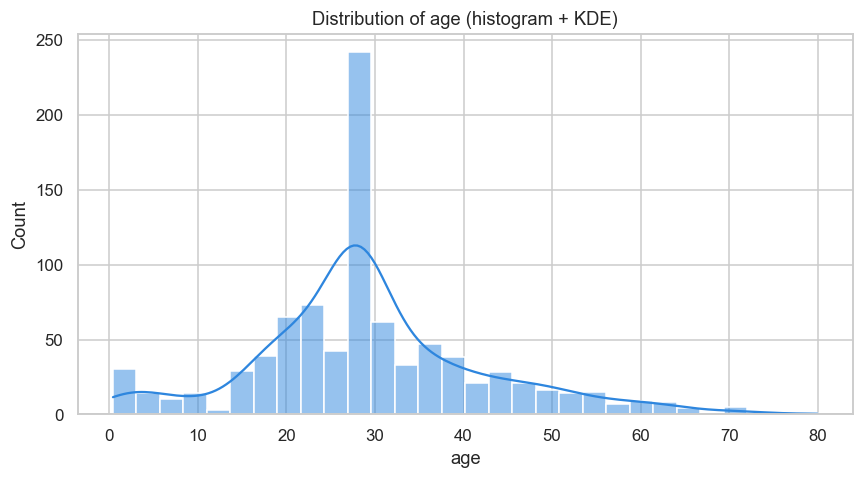

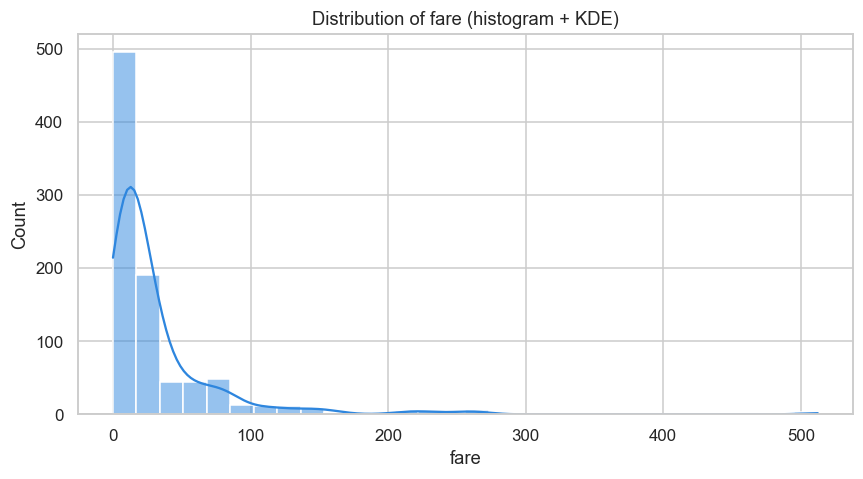

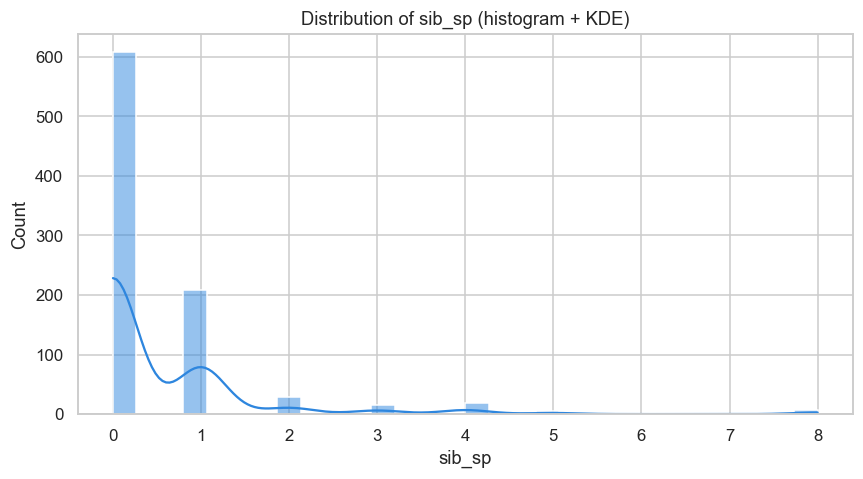

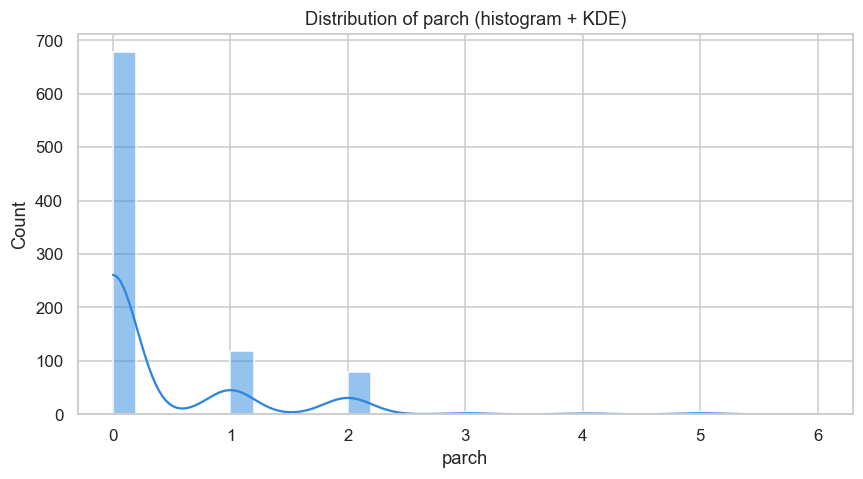

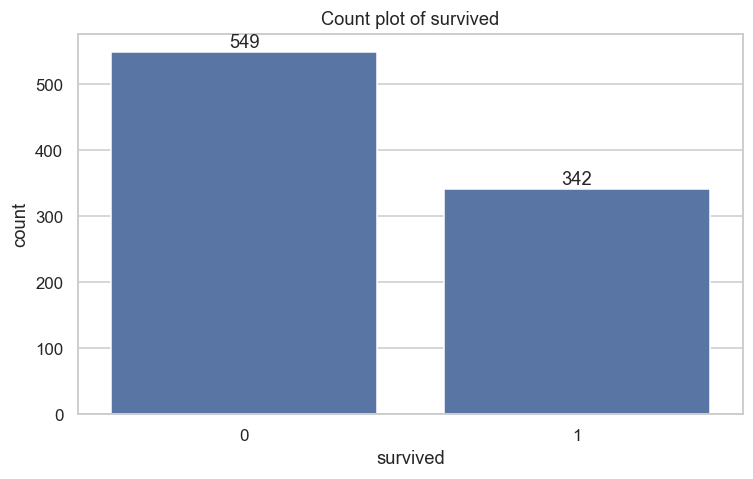

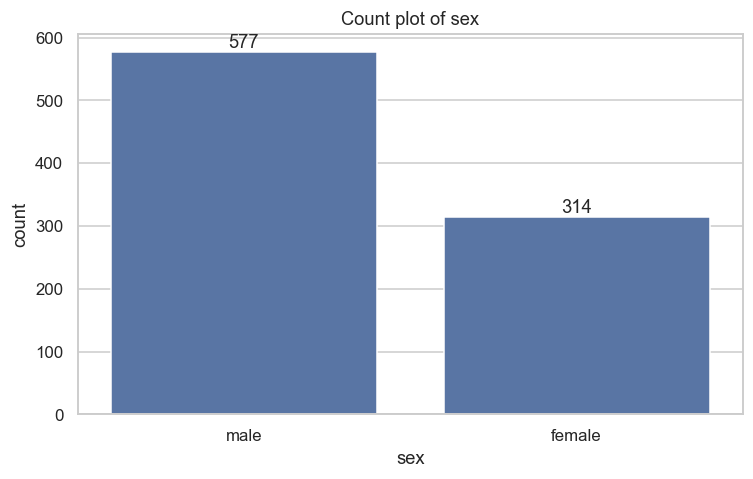

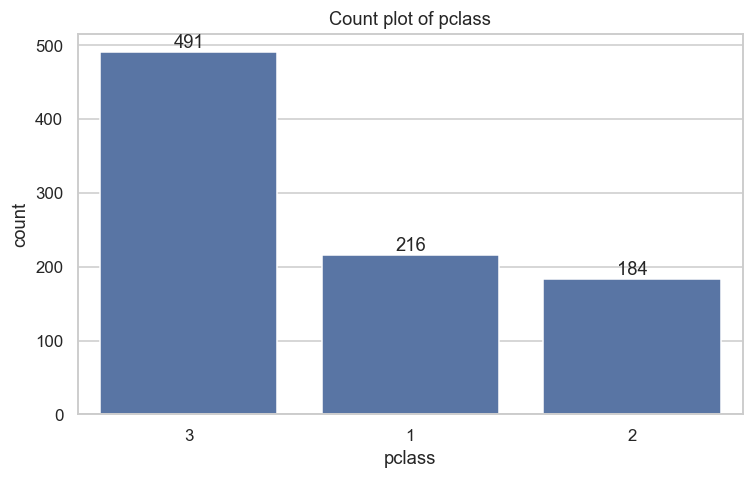

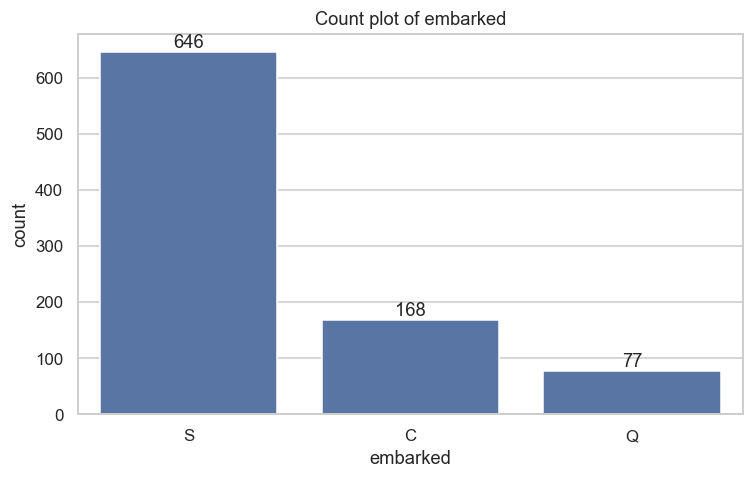

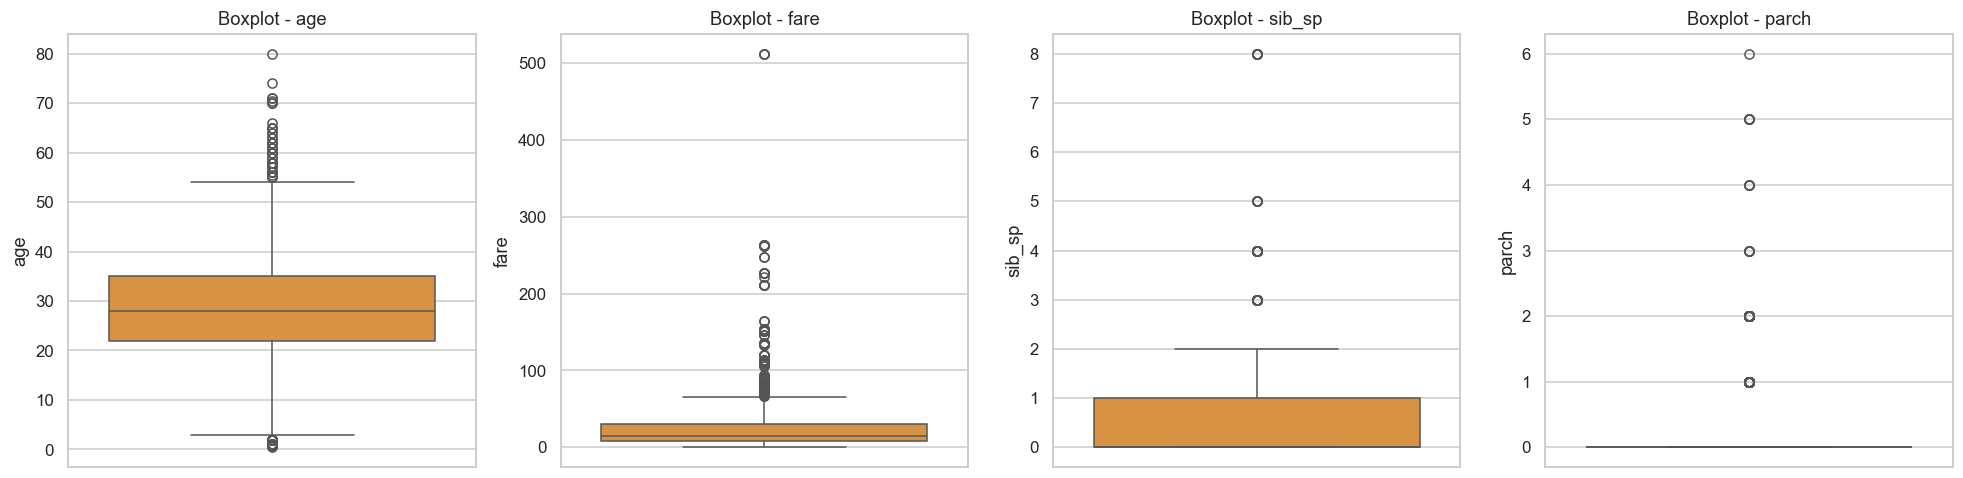

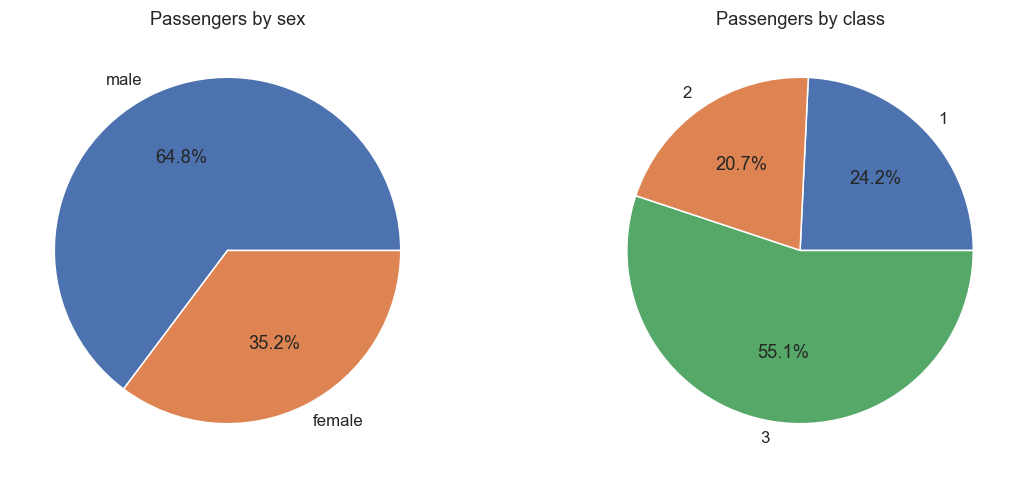

In [9]:
main.task8_univariate(df_clean)

## Task 9: Bivariate Analysis

- **Numerical vs Numerical:** scatter plot (`age` vs `fare`), correlation heatmap.
- **Categorical vs Numerical:** bar plots (mean fare/age by class), box plot
  (age by survived), violin plot (fare by sex, split by survived).
- **Categorical vs Categorical:** stacked count plots (survival by sex and class).


PART 3 - TASK 9: BIVARIATE ANALYSIS
  [chart saved] charts/task9_scatter_age_fare.png
  [chart saved] charts/task9_correlation_heatmap.png

Correlation matrix:
          age  fare  sib_sp  parch
age     1.00  0.10   -0.23  -0.17
fare    0.10  1.00    0.16   0.22
sib_sp -0.23  0.16    1.00   0.41
parch  -0.17  0.22    0.41   1.00
  [chart saved] charts/task9_bar_mean_by_class.png
  [chart saved] charts/task9_boxplot_age_by_survived.png
  [chart saved] charts/task9_violin_fare_by_sex.png
  [chart saved] charts/task9_countplot_survival_by_sex_class.png

Survival rate by sex:
       sex survival_rate
0  female         74.2%
1    male         18.9%

Survival rate by pclass:
   pclass survival_rate
0      1         63.0%
1      2         47.3%
2      3         24.2%


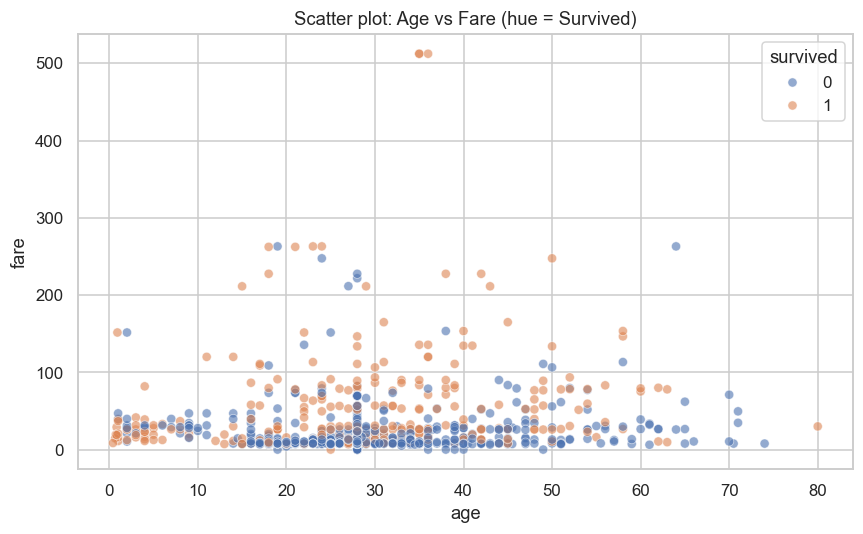

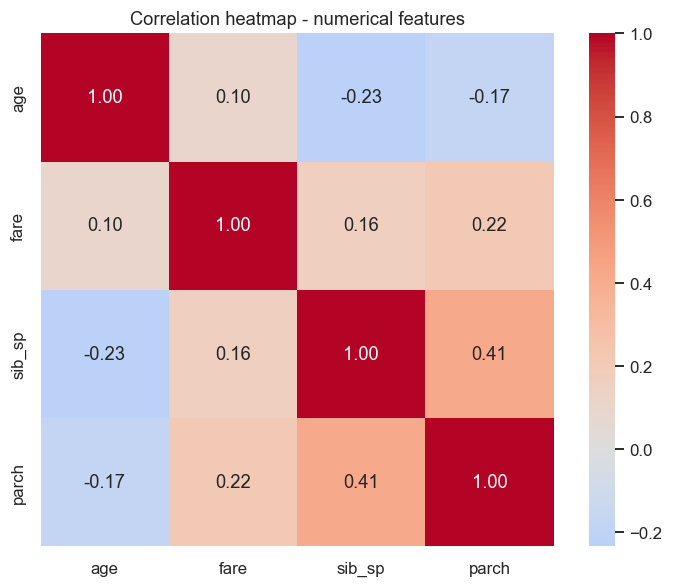

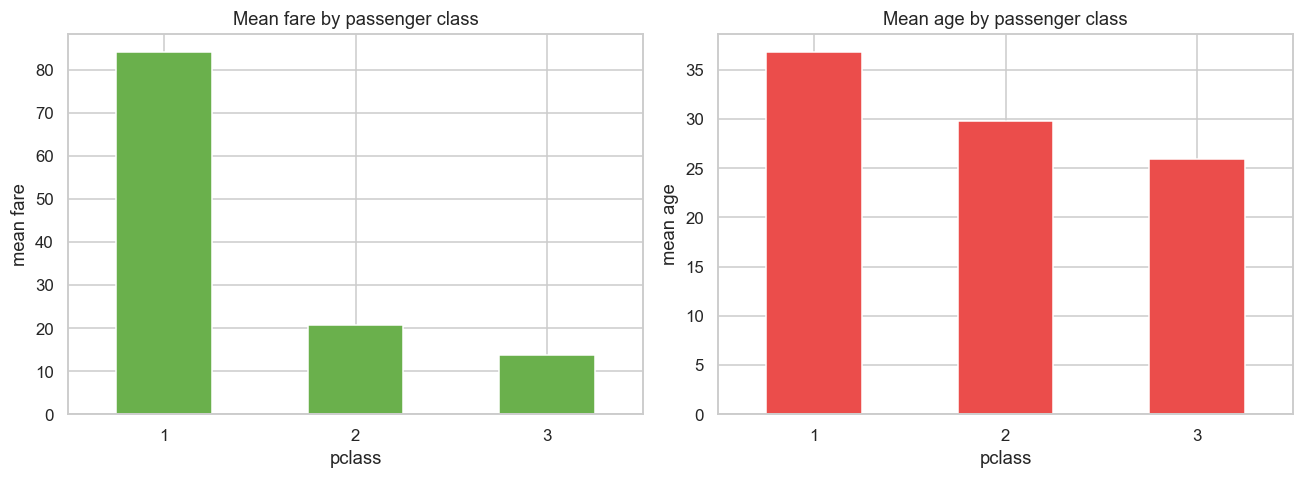

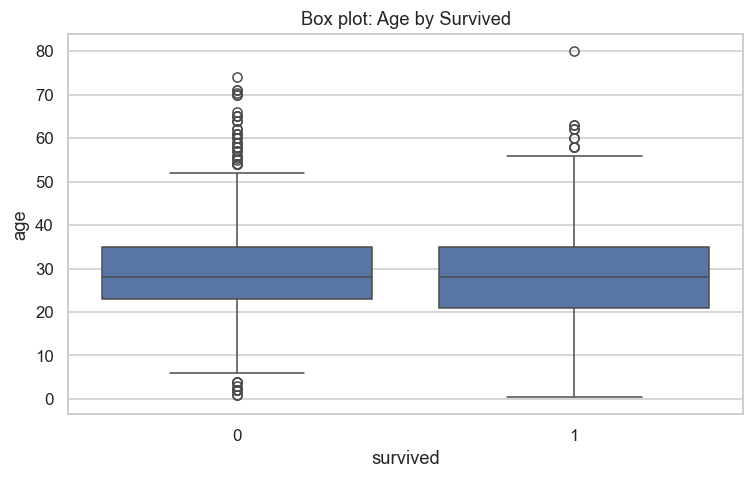

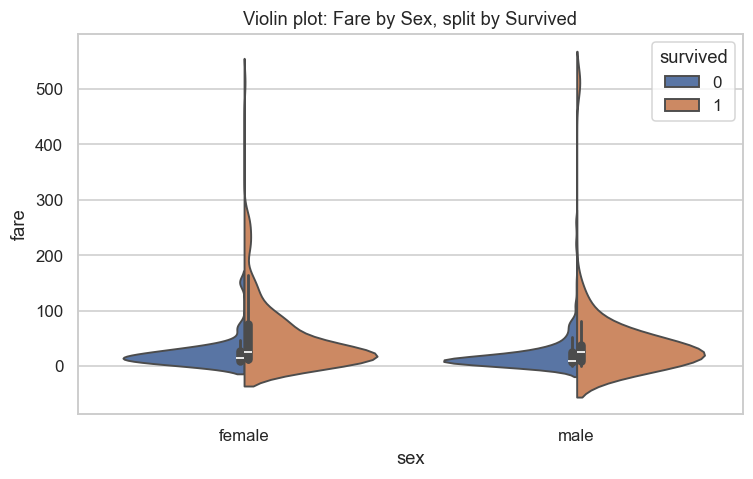

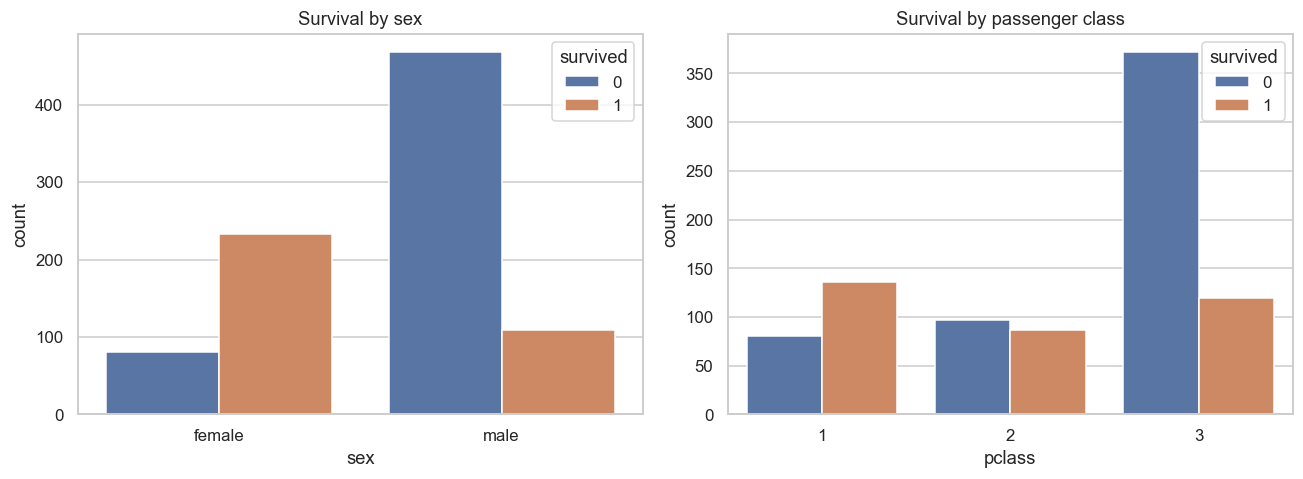

In [10]:
main.task9_bivariate(df_clean)

## Task 10: Insights & Observations

(Also saved to `INSIGHTS.md` and `README.md`.)


## PART 3 - TASK 10: Insights & Observations

Based on the EDA of the Kaggle **Titanic** dataset, here are the key insights:

1. **Gender is the strongest survival signal.** Females had a much higher survival
   rate than males, which is visible in both the survival-by-sex count plot and the
   violin plot (fare split by sex and survival).

2. **Socio-economic class strongly drives survival.** 1st-class passengers survived
   at a far higher rate than 3rd-class passengers - see the survival-by-pclass
   count plot and the mean-fare-by-class bar chart.

3. **Fare is right-skewed with extreme outliers.** The fare boxplot shows many
   points beyond the upper whisker (outliers detected with the IQR method). A few
   passengers paid several times the typical fare, which could distort a mean-based
   model - the median is the safer summary statistic here.

4. **Age contains a large block of missing values.** 177 of 891 ages were missing
   (~20%); they were imputed with the median in Task 6. Cabin was ~77% missing and
   was filled with "Unknown", making it of limited modelling value without extra
   feature work.

5. **Fare is moderately correlated with survival**, and it is tightly linked to
   passenger class (higher class -> higher fare). The correlation heatmap shows
   weak direct correlations among age/fare/sib_sp/parch, meaning the variables
   carry mostly independent information.

6. **Embarked and cabin are data-quality problem columns.** Embarked had 2 missing
   values (imputed with the mode 'S'); Cabin is mostly missing. Both need careful
   handling or feature engineering before any model is trained.

7. **The dataset is clean in most other respects.** No duplicate rows were found,
   and the numerical columns were stored in correct formats (only label columns
   were converted to `category` for clarity).

8. **Target class is imbalanced** (~62% did not survive, ~38% survived). Any future
   model should be evaluated with class imbalance in mind (e.g. stratified splits,
   precision/recall instead of accuracy alone).


In [11]:
main.task10_insights()


PART 3 - TASK 10: INSIGHTS & OBSERVATIONS (see INSIGHTS.md / README / notebook)
## PART 3 - TASK 10: Insights & Observations

Based on the EDA of the Kaggle **Titanic** dataset, here are the key insights:

1. **Gender is the strongest survival signal.** Females had a much higher survival
   rate than males, which is visible in both the survival-by-sex count plot and the
   violin plot (fare split by sex and survival).

2. **Socio-economic class strongly drives survival.** 1st-class passengers survived
   at a far higher rate than 3rd-class passengers - see the survival-by-pclass
   count plot and the mean-fare-by-class bar chart.

3. **Fare is right-skewed with extreme outliers.** The fare boxplot shows many
   points beyond the upper whisker (outliers detected with the IQR method). A few
   passengers paid several times the typical fare, which could distort a mean-based
   model - the median is the safer summary statistic here.

4. **Age contains a large block of missing values.** 17